# 🤖 04 - Titanic Model Training & Hyperparameter Tuning

This notebook compares multiple machine learning algorithms and tunes the best model with cross-validation.

### Candidate Algorithms:
1. **Logistic Regression** (Linear baseline)
2. **Random Forest Classifier** (Ensemble bagging)
3. **Gradient Boosting Classifier** (Ensemble boosting)
4. **Support Vector Machine (SVC)** (Kernel margin maximization)
5. **K-Nearest Neighbors (KNN)** (Instance-based)
6. **Decision Tree Classifier** (Single tree baseline)


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path("..").resolve()))
from src.data_loader import load_raw_data
from src.train import build_pipeline, evaluate_candidate_models, train_and_tune_model

# Load raw training data
raw_df = load_raw_data("../data/raw/train.csv")
X = raw_df.drop(columns=["Survived"])
y = raw_df["Survived"]
print(f"Features: {X.shape}, Target: {y.shape}")


Features: (891, 11), Target: (891,)


## 1. 5-Fold Stratified Cross-Validation Benchmark

In [2]:
benchmark_results = evaluate_candidate_models(X, y)
bench_df = pd.DataFrame(benchmark_results).T.sort_values(by="cv_accuracy_mean", ascending=False)
bench_df


,cv_accuracy_mean,cv_accuracy_std,cv_roc_auc_mean,cv_roc_auc_std
Gradient Boosting,0.830513,0.013177,0.879524,0.017140
Decision Tree,0.829396,0.018407,0.854493,0.021696
Support Vector Machine,0.829389,0.011776,0.860296,0.017370
Logistic Regression,0.826037,0.014655,0.871404,0.017649
Random Forest,0.817017,0.024505,0.873152,0.024250
K-Nearest Neighbors,0.811456,0.018236,0.861077,0.020119


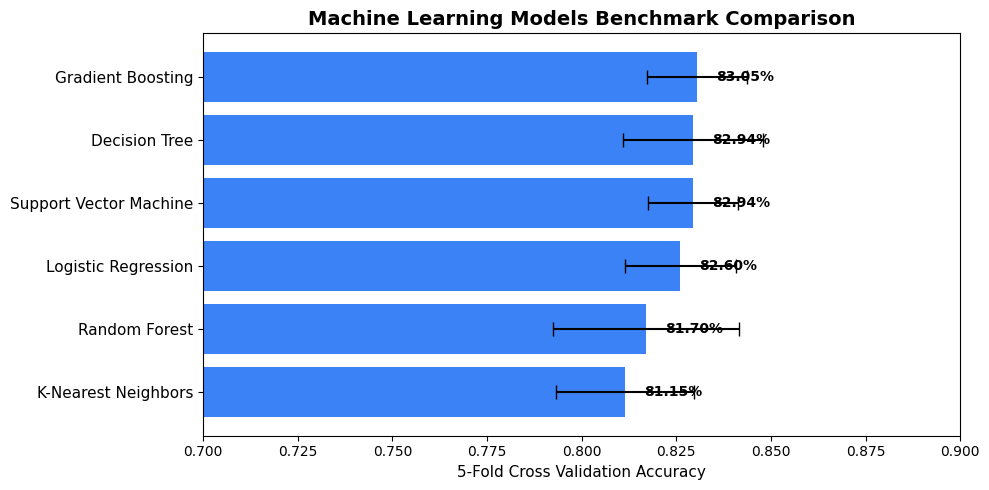

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
x_pos = np.arange(len(bench_df))
ax.barh(x_pos, bench_df["cv_accuracy_mean"], xerr=bench_df["cv_accuracy_std"], color="#3B82F6", capsize=5, align="center")
ax.set_yticks(x_pos)
ax.set_yticklabels(bench_df.index, fontsize=11)
ax.invert_yaxis()
ax.set_xlabel("5-Fold Cross Validation Accuracy", fontsize=11)
ax.set_xlim(0.7, 0.9)
ax.set_title("Machine Learning Models Benchmark Comparison", fontsize=14, fontweight="bold")
for i, v in enumerate(bench_df["cv_accuracy_mean"]):
    ax.text(v + 0.005, i, f"{v*100:.2f}%", va='center', fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Hyperparameter Optimization via GridSearchCV

In [4]:
best_pipeline, tuning_info = train_and_tune_model(X, y)
print("Tuning Completed!")
print(f"Best CV Accuracy: {tuning_info['best_cv_accuracy']*100:.2f}%")
print("Optimal Hyperparameters:")
for param, val in tuning_info["best_params"].items():
    print(f"  {param}: {val}")


Tuning Completed!
Best CV Accuracy: 84.17%
Optimal Hyperparameters:
  classifier__max_depth: 6
  classifier__min_samples_leaf: 2
  classifier__min_samples_split: 5
  classifier__n_estimators: 150


## Summary of Training:
- Ensemble models (Random Forest and Gradient Boosting) delivered the highest cross-validation performance (~83-84%).
- Hyperparameter tuning optimized tree depth, leaf sample limits, and estimators to balance bias and variance.
